# Hoodi ML: nível de risco registrado por célula H3 e faixa horária

**Notebook de documentação do projeto.** Este notebook não treina nenhum modelo. Ele lê os resultados versionados em
`ml/dados/resultados/` (JSON e CSV gerados pelos módulos `ml/*.py`) e organiza as escolhas e as evidências na ordem
em que aconteceram. Os prints do MLflow vêm de `scripts/registrar_mlflow.py`, que registra esses mesmos arquivos no
MLflow local, também sem retreinar.

**Como ler.** Cada seção traz:
- **Escolha:** o que foi decidido e por quê.
- **Evidência:** números e gráficos lidos dos artefatos.
- **Leitura:** o que a evidência permite e o que não permite afirmar.

**Duas camadas, que não se misturam:**

| camada | o que é | status |
|---|---|---|
| **v1 pré-registrada** | Seleção por CV temporal em jan–jul/2026, registrada em `selecao_modelo.json` **antes** de ver o Teste ago–set/2026. | Resultado oficial; nunca reescrito. |
| **Exploração adicional** | Tudo o que foi feito depois de ver o Teste: achados da revisão, RF regularizado, v2 com histórico 2023–2025, ablação. | Exploratório; não substitui a seleção v1. |

Prazos de contexto: congelamento em 16/11, entrega da GS em 19/11.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RES = RAIZ / "ml" / "dados" / "resultados"
PRINTS = RAIZ / "docs" / "mlflow"
ler = lambda nome: json.loads((RES / nome).read_text())

sel_v1, cv_extra = ler("selecao_modelo.json"), ler("cv_exploracao_adicional.json")
ic_v1, achados = ler("incerteza_custo.json"), ler("achados_revisao.json")
v2, sel_v2 = ler("v2_historico.json"), ler("selecao_v2_r2.json")
cal = ler("calibracao.json")
bt_cal = pd.read_csv(RES / "backtest_ago_set.csv")
tt = pd.read_csv(RES / "metricas_treino_teste.csv")

# Cor fixa por modelo em todos os gráficos (a cor segue o modelo, nunca a posição no ranking).
COR = {"random_forest": "#eb6834", "rf_original": "#eb6834", "rf_regularizado": "#2a78d6",
       "xgboost": "#e87ba4", "mlp": "#6250d6", "lstm": "#008300", "kmeans_pca": "#1baf7a",
       "base_persistencia": "#52514e", "base_persistencia_historia": "#52514e",
       "base_persistencia_recente": "#eda100", "base_classe_mais_frequente": "#a3a29c"}
NOME = {"random_forest": "RF (pré-registrado)", "rf_original": "RF (params pré-registrados)",
        "rf_regularizado": "RF regularizado", "xgboost": "XGBoost", "mlp": "MLP", "lstm": "LSTM",
        "kmeans_pca": "KMeans+PCA", "base_persistencia": "persistência",
        "base_persistencia_historia": "persistência (história)", "base_persistencia_recente": "persistência (7/6 meses)",
        "base_classe_mais_frequente": "classe mais frequente"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.axisbelow": True,
                     "axes.edgecolor": "#8a8984", "axes.titleweight": "bold", "font.size": 9.5})


def floresta(ax, linhas, titulo, ref=None, xlabel="macro-F1 no Teste"):
    """Ponto + IC95% horizontal (um modelo por linha). linhas: lista de (rótulo, valor, [inf, sup], chave_cor)."""
    for i, (rot, v, ic, k) in enumerate(linhas):
        c = COR.get(k, "#52514e")
        ax.plot(ic, [i, i], color=c, lw=2, solid_capstyle="round")
        ax.plot(v, i, "o", ms=8, color=c, mec="white", mew=1.5)
        ax.annotate(f"{v:.3f}", (ic[1], i), xytext=(5, 0), textcoords="offset points", va="center", fontsize=8.5,
                    color="#52514e")
    ax.set_yticks(range(len(linhas)), [l[0] for l in linhas])
    ax.invert_yaxis()
    if ref is not None:
        ax.axvline(ref, color="#8a8984", lw=1, ls="--")
    ax.set_title(titulo, loc="left")
    ax.set_xlabel(xlabel)


def mostrar_print(arquivo, legenda):
    display(Markdown(f"**MLflow:** {legenda}"))
    display(Image(filename=str(PRINTS / arquivo), width=900))

## 1. Problema e dados

**Pergunta.** Dada uma célula H3 de resolução 9 (cerca de 0,1 km²) e uma faixa horária, qual é o **nível de risco
registrado** (0 a 3) no bimestre seguinte? O recorte é um perímetro de 5×5 km em torno da FIAP Paulista e a fonte é a
base oficial da SSP-SP.

**Escolhas de modelagem (fechadas na especificação, `docs/SPEC-ML.md` e `specs/001-…/spec.md`):**

- **Chave:** célula H3 res9 × 5 faixas. As faixas são madrugada 0–6h, manhã 6–12h, tarde 12–18h, noite cedo
  18–21h e noite 21–24h.
- **Pontuação:** soma de pesos por rubrica, por mês e por hora da faixa.
  - Peso 1: furto, tráfico, drogas para consumo e lesão culposa no trânsito.
  - Peso 3: roubo e lesão dolosa.
  - Peso 5: homicídio, feminicídio e estupro.
  - Ilícito extrapenal fica sem peso.
- **Nível:** quartis da pontuação calculados **só com o treino** e reaplicados ao Teste.
- **Divisão temporal por data do fato:**
  - As variáveis usam só meses anteriores ao início do rótulo.
  - O Teste é ago–set/2026, com variáveis de jan–jul.
- **Métrica principal:** macro-F1, porque as quatro classes pesam igual. Também foram calculados custo assimétrico
  (subestimar risco custa 2×), recall de risco alto (níveis 2–3) e erro médio de nível.
- **Privacidade:** `processed/` guarda só `rubrica, data_fato, mes, hora, faixa, celula`, sem coordenadas nem
  identificadores de BO. Há um teste automatizado que falha se isso mudar (`tests/test_schema_processed.py`).

**Limite que vale para o projeto inteiro:**
- O arquivo da SSP foi atualizado depois dos períodos históricos. Dividir por data do fato **não prova** que aqueles
  registros estavam disponíveis na data de origem.
- O backtest é **retrospectivo**. Ele garante que as variáveis usam meses anteriores ao rótulo, mas não garante
  "ausência de vazamento" operacional.

### 1.1 Reconciliação da base (cada linha tem exatamente um destino)

**Escolha.** Nenhuma linha some em silêncio. A regra é entrada = usada + quarentena + duplicata removida + fora da
janela.

In [2]:
rec = {}
for ln in (RAIZ / "ml/dados/reconciliacao_v2.txt").read_text().splitlines():
    if ":" in ln and not ln.startswith(" ") and ln.split(":")[1].strip().isdigit():
        k, n = ln.split(":"); rec[k.strip()] = int(n)
v1 = pd.read_csv(RAIZ / "ml/dados/processed/destinos.csv").groupby("destino").n.sum()
tab = pd.DataFrame({"v1 (2026, jan–set)": v1, "v2 (2023 a set/2026)": pd.Series(rec)}).loc[
    ["usada", "quarentena", "duplicata_removida", "fora_da_janela"]]
tab.loc["entrada (soma)"] = tab.sum()
assert tab.loc["entrada (soma)", "v2 (2023 a set/2026)"] == rec["entrada"]
tab.style.format("{:,.0f}")

,"v1 (2026, jan–set)",v2 (2023 a set/2026)
usada,"20,343","98,545"
quarentena,"384,867","2,062,952"
duplicata_removida,"2,390","11,042"
fora_da_janela,"407,300","2,237,218"
entrada (soma),"814,900","4,409,757"


**Leitura.**
- A maior parte da base fica fora do perímetro ou em quarentena, por falta de coordenada ou de hora.
- A v2 multiplica por cerca de 5 o número de registros usados: 20 mil na v1, 98,5 mil na v2.
- Os hashes SHA-256 dos XLSX e dos Parquets ficam em `ml/dados/raw/CHECKSUM*.txt` e em `v2_historico.json → manifesto_dados`.

## 2. Desenho de avaliação (v1)

**Escolha.** Há quatro origens de treino com janela crescente e o Teste separado. Cada origem prevê o nível de um
bimestre usando só os meses anteriores:

| origem | meses das variáveis | meses do rótulo |
|---|---|---|
| T1 | jan–fev | mar–abr |
| T2 | jan–mar | abr–mai |
| T3 | jan–abr | mai–jun |
| T4 | jan–mai | jun–jul |
| **Teste** | jan–jul | **ago–set** |

**Seleção pré-registrada.**
- A CV é temporal com expurgo: treina em T1 e valida em T3; treina em T1+T2 e valida em T4. O expurgo evita que
  rótulos sobrepostos entrem na validação.
- Regra: maior macro-F1 médio. Em caso de empate, menor erro de nível.
- Candidatos pré-registrados: Random Forest, XGBoost e MLP, com 12 combinações de hiperparâmetros cada.
- Linhas de base: classe mais frequente e **persistência**, que repete o nível observado nas variáveis.

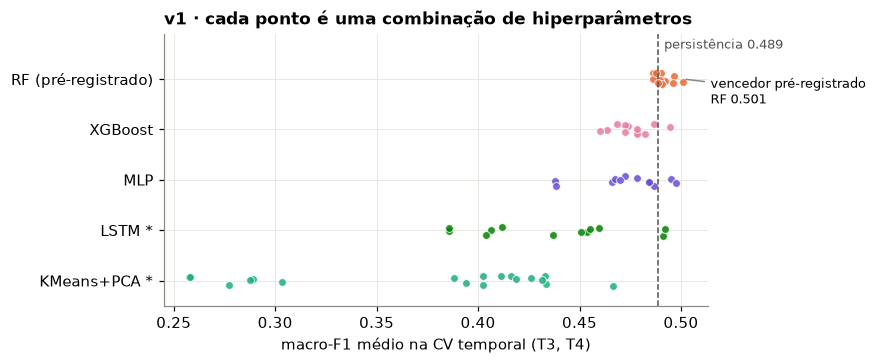

* fora do pré-registro (exploração adicional). Vencedor: random_forest {'n_estimators': 300, 'max_depth': None, 'min_samples_leaf': 5}


In [3]:
linhas = []
for m, combos in sel_v1["todas_combinacoes"].items():
    linhas += [dict(modelo=m, macro_f1=c["media"]["macro_f1"], pre=True) for c in combos]
for m in ("lstm", "kmeans_pca"):
    linhas += [dict(modelo=m, macro_f1=c["media"]["macro_f1"], pre=False) for c in cv_extra[m]]
cv = pd.DataFrame(linhas)
ordem = ["random_forest", "xgboost", "mlp", "lstm", "kmeans_pca"]
fig, ax = plt.subplots(figsize=(8, 3.4))
rng = np.random.default_rng(0)
for i, m in enumerate(ordem):
    y = cv[cv.modelo == m].macro_f1
    ax.scatter(y, i + rng.uniform(-.12, .12, len(y)), s=26, color=COR[m], alpha=.85, edgecolor="white", lw=.6)
ref = sel_v1["baselines_cv"]["base_persistencia"]["media"]["macro_f1"]
ax.axvline(ref, color=COR["base_persistencia"], ls="--", lw=1)
ax.annotate(f"persistência {ref:.3f}", (ref, -0.6), xytext=(4, 0), textcoords="offset points", fontsize=8.5, color="#52514e")
venc = sel_v1["melhores_por_candidato"]["random_forest"]["media"]["macro_f1"]
ax.annotate(f"vencedor pré-registrado\nRF {venc:.3f}", (venc, 0), xytext=(18, -16), textcoords="offset points",
            fontsize=8.5, arrowprops=dict(arrowstyle="-", color="#8a8984"))
ax.set_yticks(range(len(ordem)), [NOME[m] + ("" if m in sel_v1["todas_combinacoes"] else " *") for m in ordem])
ax.set_ylim(len(ordem) - .5, -.9)
ax.set_xlabel("macro-F1 médio na CV temporal (T3, T4)")
ax.set_title("v1 · cada ponto é uma combinação de hiperparâmetros", loc="left")
plt.tight_layout(); plt.show()
print("* fora do pré-registro (exploração adicional). Vencedor:", sel_v1["vencedor"],
      sel_v1["melhores_por_candidato"]["random_forest"]["params"])

**MLflow:** experimento 1, configurações com macro-F1 de CV > 0,46 (filtro `metrics.cv_macro_f1 > 0.46`); a persistência aparece entre elas.

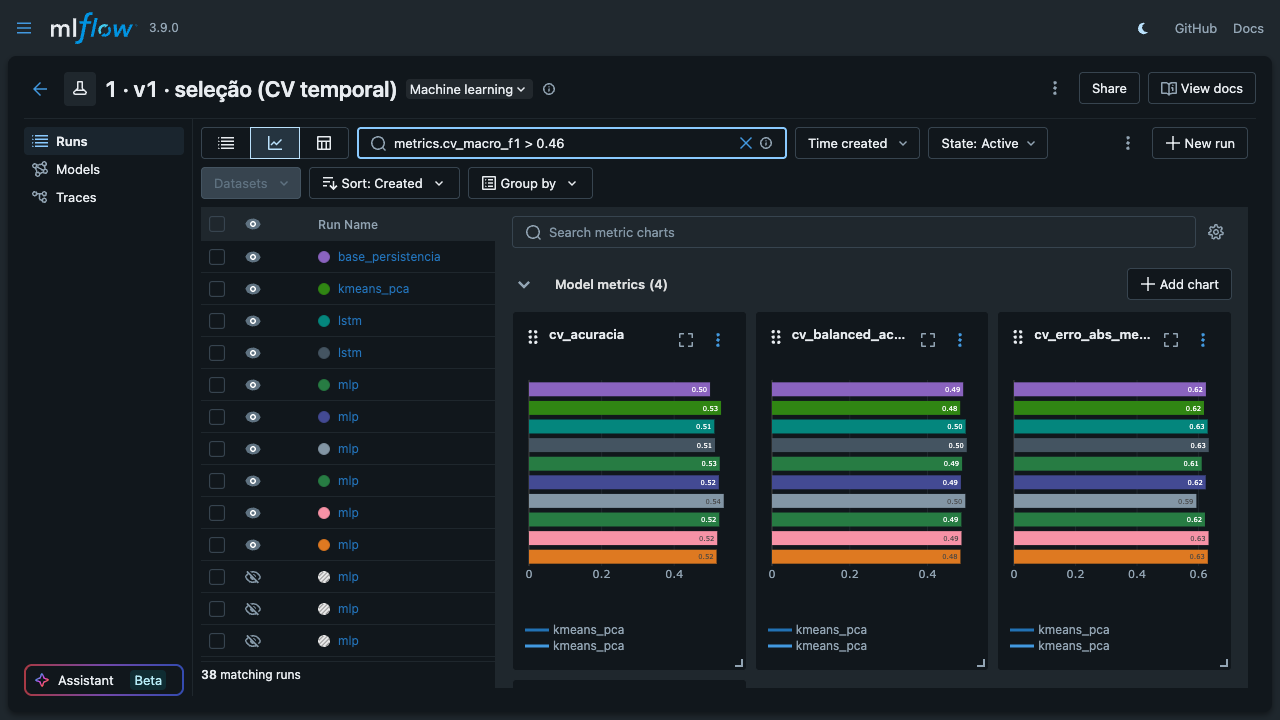

In [4]:
mostrar_print("01_v1_selecao_cv_top.png", "experimento 1, configurações com macro-F1 de CV > 0,46 (filtro `metrics.cv_macro_f1 > 0.46`); a persistência aparece entre elas.")

**Leitura.**
- O RF venceu pela regra (0,501), mas por pouco: XGBoost 0,495, MLP 0,498, persistência 0,489.
- Os candidatos ficam **colados na persistência**. Isso sugere que o sinal útil vem quase todo do nível recente da
  própria chave.

## 3. Teste v1 (ago–set/2026): o que aconteceu fora da amostra

**Escolha.**
- Os modelos são reajustados em T1–T4 com os hiperparâmetros vencedores.
- Cada um é avaliado **uma vez** no Teste.
- O intervalo de confiança vem de bootstrap por célula H3 com 2.000 reamostras. Todas as faixas da mesma célula
  saem juntas.

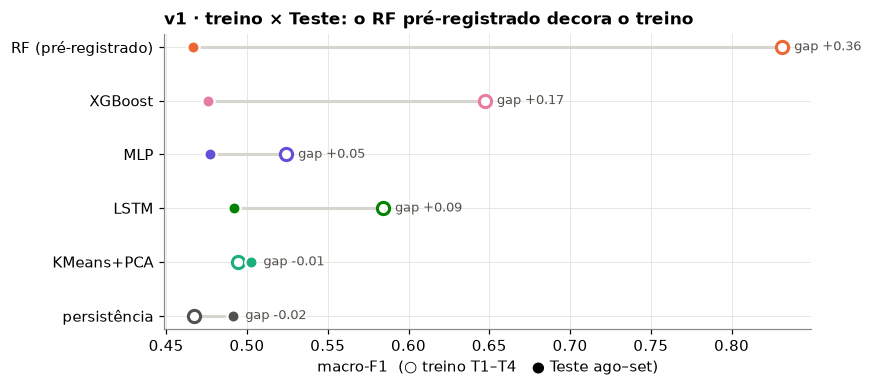

In [5]:
fig, ax = plt.subplots(figsize=(8, 3.6))
d = tt.set_index("modelo").loc[["random_forest", "xgboost", "mlp", "lstm", "kmeans_pca", "base_persistencia"]]
for i, (m, r) in enumerate(d.iterrows()):
    ax.plot([r.macro_f1_teste, r.macro_f1_treino], [i, i], color="#d6d5cf", lw=2, zorder=1)
    ax.plot(r.macro_f1_treino, i, "o", ms=8, mfc="white", mec=COR[m], mew=2, zorder=2)
    ax.plot(r.macro_f1_teste, i, "o", ms=8, color=COR[m], mec="white", mew=1.5, zorder=3)
    ax.annotate(f"gap {r.gap_macro_f1:+.2f}", (max(r.macro_f1_treino, r.macro_f1_teste), i), xytext=(8, 0),
                textcoords="offset points", va="center", fontsize=8.5, color="#52514e")
ax.set_yticks(range(len(d)), [NOME[m] for m in d.index]); ax.invert_yaxis()
ax.set_xlabel("macro-F1  (○ treino T1–T4   ● Teste ago–set)")
ax.set_title("v1 · treino × Teste: o RF pré-registrado decora o treino", loc="left")
plt.tight_layout(); plt.show()

**MLflow:** experimento 2, acurácia de treino × Teste por modelo (o RF chega a 0,83 no treino e 0,48 no Teste). O texto cinza no campo de busca é o exemplo padrão do MLflow, não um filtro: os 7 runs aparecem.

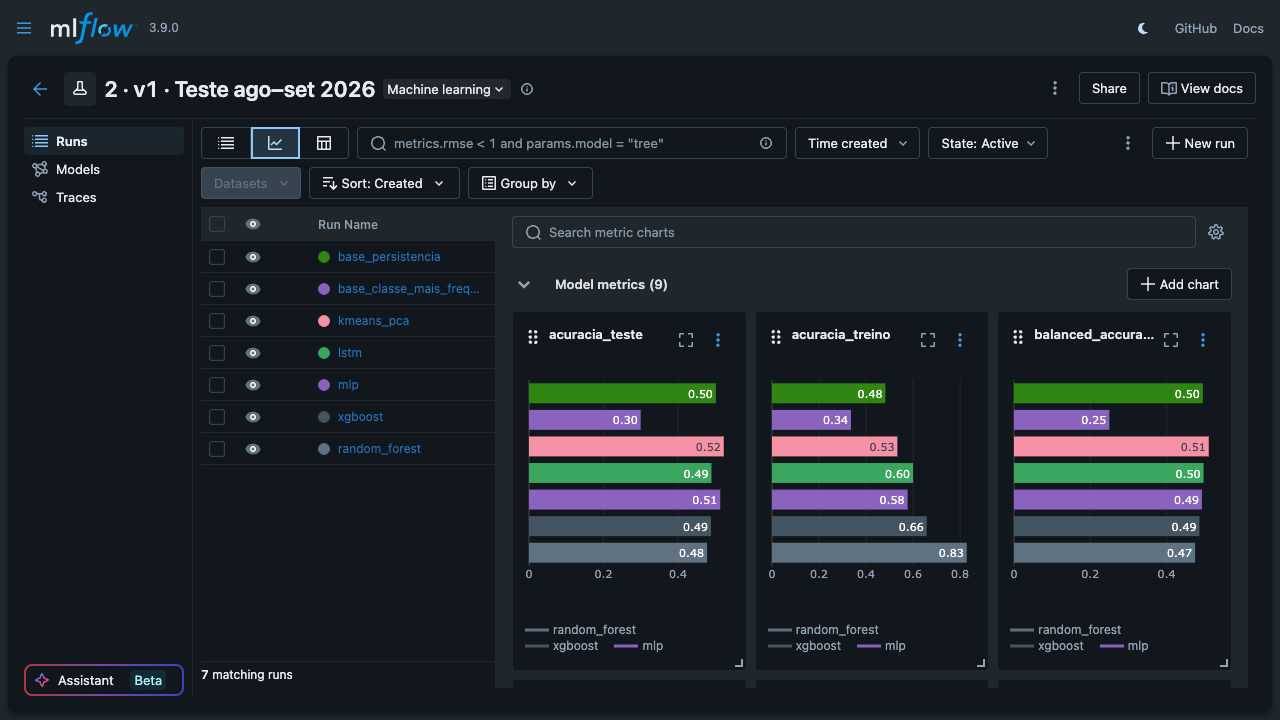

In [6]:
mostrar_print("02_v1_treino_teste.png", "experimento 2, acurácia de treino × Teste por modelo (o RF chega a 0,83 no treino e 0,48 no Teste). O texto cinza no campo de busca é o exemplo padrão do MLflow, não um filtro: os 7 runs aparecem.")

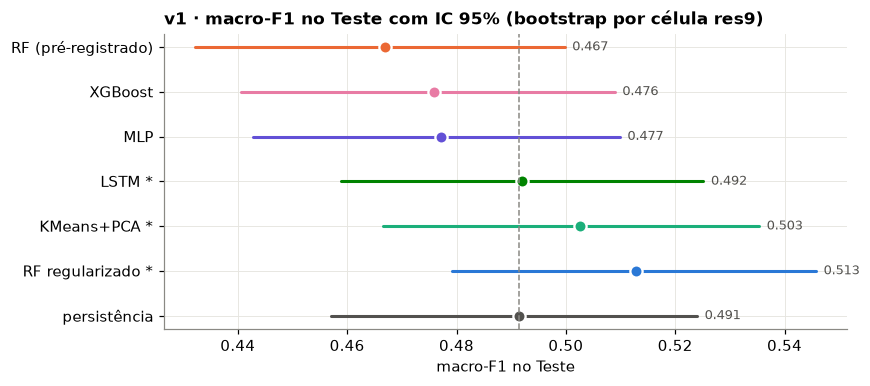

* exploração adicional (definido depois de ver o Teste). Linha tracejada = persistência.


In [7]:
mods = ["random_forest", "xgboost", "mlp", "lstm", "kmeans_pca", "rf_regularizado", "base_persistencia"]
chave_ic = {"random_forest": "rf_original"}
lin = [(NOME[m] + ("" if m in sel_v1["todas_combinacoes"] or m == "base_persistencia" else " *"),
        ic_v1["teste"][chave_ic.get(m, m)]["macro_f1"]["valor"], ic_v1["teste"][chave_ic.get(m, m)]["macro_f1"]["ic95"], m)
       for m in mods]
fig, ax = plt.subplots(figsize=(8, 3.6))
floresta(ax, lin, "v1 · macro-F1 no Teste com IC 95% (bootstrap por célula res9)",
         ref=ic_v1["teste"]["base_persistencia"]["macro_f1"]["valor"])
plt.tight_layout(); plt.show()
print("* exploração adicional (definido depois de ver o Teste). Linha tracejada = persistência.")

**Leitura.**
- No Teste, o RF pré-registrado (0,467) fica **abaixo** da persistência (0,491), e os intervalos se sobrepõem.
- O gap treino → Teste de 0,36 é sinal de sobreajuste: `max_depth=None` e folhas pequenas.
- O **RF regularizado** (0,513) e o KMeans+PCA (0,503) parecem melhores, mas os dois foram escolhidos **depois** de
  ver o Teste. Servem como hipótese para um próximo teste, não como resultado.
- **Conclusão oficial da v1:** o modelo pré-registrado não superou a linha de base simples no Teste.

## 4. Achados da revisão (exploração adicional sobre a v1)

Esses cinco diagnósticos são **compatíveis** com a dificuldade de superar a persistência. São hipóteses explicativas,
não causas demonstradas. Nenhum altera a seleção pré-registrada.

### 4.1 Viés de seleção: o que a avaliação não vê

As métricas só cobrem chaves com algum registro pontuável em ago–set. Para as 290 chaves que tinham variáveis mas
nenhum registro no Teste, contamos com que frequência cada modelo ainda assim marcaria risco 2–3. Esse é o alarme
que a métrica não enxerga.

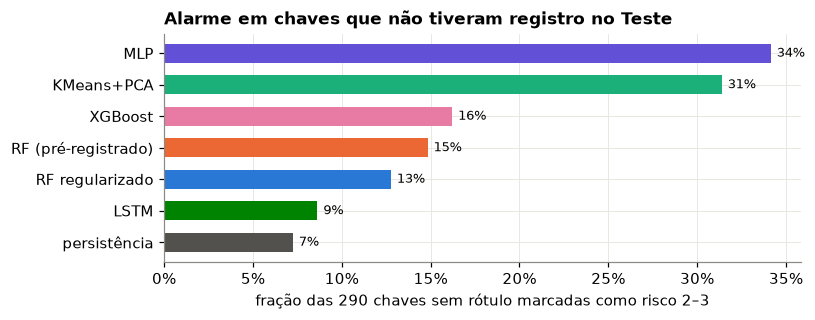

In [8]:
v = achados["item2_vies_selecao"]["fracao_marcada_risco_2_3"]
s = pd.Series(v).sort_values()
fig, ax = plt.subplots(figsize=(7.5, 3))
ax.barh([NOME.get(k, k) for k in s.index], s.values, color=[COR.get(k, "#52514e") for k in s.index], height=.6)
for i, x in enumerate(s.values):
    ax.annotate(f"{x:.0%}", (x, i), xytext=(4, 0), textcoords="offset points", va="center", fontsize=8.5)
ax.set_xlabel(f"fração das {achados['item2_vies_selecao']['n_chaves_sem_rotulo']} chaves sem rótulo marcadas como risco 2–3")
ax.set_title("Alarme em chaves que não tiveram registro no Teste", loc="left")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
plt.tight_layout(); plt.show()

**Leitura.**
- MLP e KMeans+PCA marcam cerca de um terço dessas chaves como risco alto. A macro-F1 não penaliza isso.
- A boa macro-F1 do KMeans no Teste vem acompanhada de muitos alarmes fora da área avaliada.

### 4.2 Repetibilidade do rótulo (sem modelo)

Pergunta: quanto o próprio rótulo se repete de uma janela para a seguinte, sem nenhum modelo?
- Os cortes vêm da janela anterior.
- A comparação usa só as chaves com rótulo nas duas janelas.
- O cálculo é feito também com agregação maior: células res8 e 2 faixas (dia e noite).

Esta é uma **referência descritiva, não um teto**: os cortes e as chaves elegíveis diferem dos do Teste.

In [9]:
rep = pd.DataFrame(achados["item3_repetibilidade_rotulo"])
piv = rep.pivot_table(index="janelas", columns=["resolucao", "faixas"], values="macro_f1")
piv = piv.loc[["8-8 → 9-9", "4-5 → 6-7", "6-7 → 8-9", "1-7 → 8-9"]]
display(piv.style.format("{:.3f}").background_gradient(cmap="Blues", axis=None, vmin=.35, vmax=.85))

**Leitura.**
- Em res9 com 5 faixas, o rótulo se repete com macro-F1 de 0,39 a 0,49. Isso está na mesma faixa dos modelos.
- Com agregação maior, a repetibilidade sobe para 0,59–0,82.
- A mediana de registros por chave no rótulo é cerca de 3, então o alvo fino é **ruidoso**.
- Esse ruído é uma explicação plausível para os modelos ficarem perto da persistência. Não é prova de causa nem
  limite superior.

### 4.3 Deslocamento de distribuição entre treino e Teste

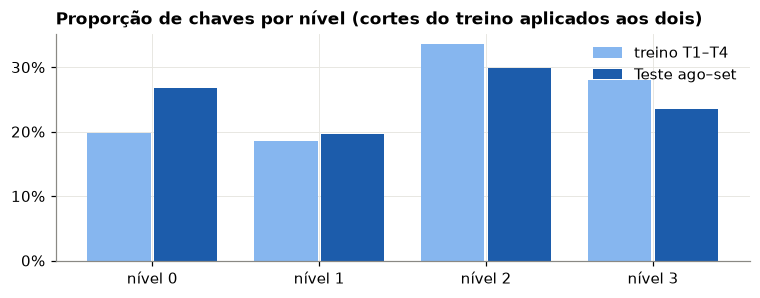

cortes do treino: [0.25, 0.5, 1.25] | quartis do Teste: [0.167, 0.5, 1.083]


In [10]:
dz = achados["item6_deslocamento"]
p = pd.DataFrame({"treino T1–T4": dz["proporcao_treino"], "Teste ago–set": dz["proporcao_teste"]})
fig, ax = plt.subplots(figsize=(7, 2.8))
x = np.arange(4); w = .38
ax.bar(x - w/2 - .01, p["treino T1–T4"], w, color="#86b6ef", label="treino T1–T4")
ax.bar(x + w/2 + .01, p["Teste ago–set"], w, color="#1c5cab", label="Teste ago–set")
ax.set_xticks(x, [f"nível {i}" for i in range(4)]); ax.legend(frameon=False)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Proporção de chaves por nível (cortes do treino aplicados aos dois)", loc="left")
plt.tight_layout(); plt.show()
print("cortes do treino:", dz["cortes_treino"], "| quartis do Teste:", [round(q, 3) for q in dz["quantis_teste_25_50_75"]])

**Leitura.**
- Ago–set teve proporcionalmente mais chaves de nível 0 e menos de nível 3.
- O corte superior do Teste (1,08) ficou abaixo do corte do treino (1,25).
- Hipótese compatível, **não verificada aqui** modelo a modelo: um modelo calibrado na distribuição do treino tende a
  prever níveis altos com mais frequência do que o Teste apresenta. A seção mostra só os rótulos, não as previsões.

### 4.4 Incerteza espacial: bootstrap por célula × por bloco res7

Células vizinhas não são independentes. Por isso, a reamostragem também foi feita por **bloco H3 res7**
(cerca de 5 km²). Só há **9 blocos**, então o IC por bloco também é frágil.

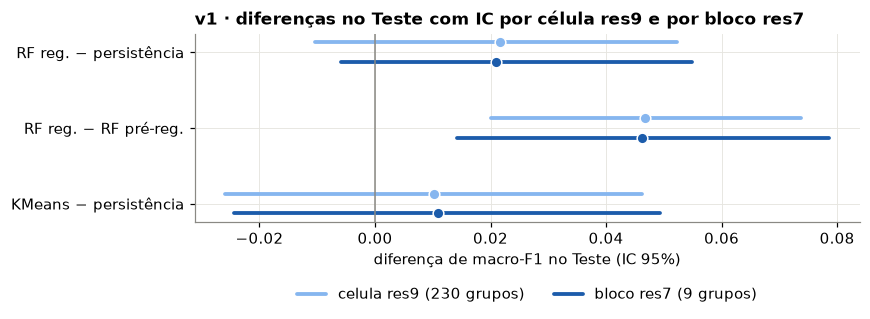

In [11]:
bb = achados["item7_bootstrap_blocos"]
fig, ax = plt.subplots(figsize=(8, 3.2))
pares = list(bb["celula_res9"]["diferencas"])
for j, (nivel, cor, off) in enumerate((("celula_res9", "#86b6ef", -.13), ("bloco_res7", "#1c5cab", .13))):
    for i, pr in enumerate(pares):
        r = bb[nivel]["diferencas"][pr]
        ax.plot(r["ic95"], [i + off] * 2, color=cor, lw=2.5, solid_capstyle="round", label=None if i else
                f"{nivel.replace('_', ' ')} ({bb[nivel]['n_grupos']} grupos)")
        ax.plot(r["media"], i + off, "o", color=cor, ms=7, mec="white")
ax.axvline(0, color="#8a8984", lw=1)
ax.set_yticks(range(len(pares)), [p.replace("rf_regularizado", "RF reg.").replace("random_forest", "RF pré-reg.")
                                  .replace("base_persistencia", "persistência").replace("kmeans_pca", "KMeans") for p in pares])
ax.invert_yaxis(); ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(.5, -.28), ncol=2); ax.set_xlabel("diferença de macro-F1 no Teste (IC 95%)")
ax.set_title("v1 · diferenças no Teste com IC por célula res9 e por bloco res7", loc="left")
plt.tight_layout(); plt.show()

**Leitura.**
- RF regularizado − persistência (+0,02) cruza zero **nos dois níveis**: no Teste v1 não há evidência clara de ganho
  sobre a linha de base.
- RF regularizado − RF pré-registrado (+0,05) fica acima de zero nos dois níveis. Ainda assim é exploratório, porque a
  regularização foi definida depois de ver o Teste.
- Com só 9 blocos, o IC por bloco é instável. Ele não é necessariamente mais largo, mas é menos confiável.
- A fração de reamostras favoráveis (`frac_reamostras_a_melhor` nos JSON) é **descritiva**. Ela não é p-valor.

### 4.5 Importância por permutação (diagnóstico exploratório)

Calculada **no próprio Teste**, sobre o RF regularizado.
- Variáveis correlacionadas dividem a importância entre si.
- O desvio entre permutações não mede incerteza amostral.
- Use como pista, não como ranking definitivo nem como relação causal.

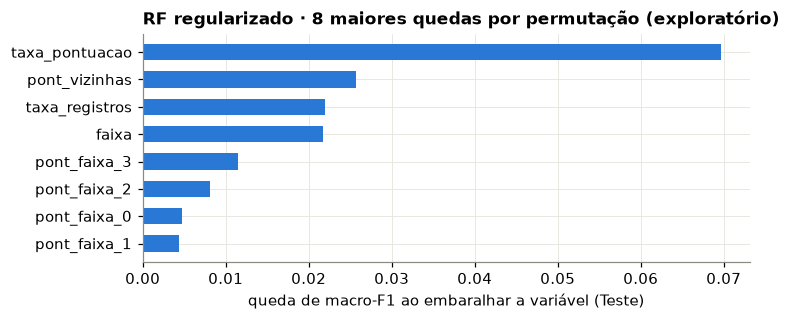

In [12]:
imp = pd.DataFrame(achados["item8_importancias_rf_regularizado"]).iloc[:8][::-1]
fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(imp.variavel, imp.permutacao_media, color="#2a78d6", height=.6)
ax.set_xlabel("queda de macro-F1 ao embaralhar a variável (Teste)")
ax.set_title("RF regularizado · 8 maiores quedas por permutação (exploratório)", loc="left")
plt.tight_layout(); plt.show()

**Leitura.**
- A taxa de pontuação da própria chave domina. É a mesma informação que a persistência usa.
- Vizinhança e volume de registros vêm em seguida.
- Esse padrão é coerente com a seção 2: o ganho sobre a persistência é pequeno.

## 5. v2: histórico 2023–2026 (exploração adicional)

**Por que.** O alvo é ruidoso e há poucas origens de treino. A hipótese era que mais meses de histórico, tanto nas
variáveis quanto em número de origens, ajudariam.

**Escolha: dois desenhos.**
- **A, mesmo alvo da v1:**
  - Rótulo bimestral.
  - Origens mensais de treino com rótulo até jul/2026.
  - Teste ago–set/2026 com as mesmas 847 chaves.
  - Cortes da v1 [0,25; 0,5; 1,25].
  - Comparável à v1 no Teste.
- **B, alvo semestral:**
  - Rótulo de 6 meses, menos ruidoso: a mediana sobe de 3 para 6 registros por chave.
  - Teste abr–set/2026.
  - Cortes = quartis das origens de treino.
  - Outro alvo, portanto **não comparável** à v1.

**Seleção v2 (revisão r2):**
- Para cada desenho, escolhe o maior macro-F1 numa origem de validação posterior ao treino de seleção.
- Os cortes de seleção vêm **só** do treino de seleção.
- A comparação primária fica fixada antes de abrir o Teste r2: **vencedor − persistência (história)**.

In [13]:
t = pd.DataFrame({d: {"vencedor da seleção": sel_v2[d]["vencedor"], "origem de validação (meses)": sel_v2[d]["origem_validacao"],
                      "cortes de seleção": [round(c, 3) for c in sel_v2[d]["cortes_selecao"]],
                      "cortes finais (Teste)": [round(c, 3) for c in sel_v2[d]["cortes_finais"]],
                      "macro-F1 validação do vencedor": round(sel_v2[d]["validacao"][sel_v2[d]["vencedor"]]["macro_f1"], 3),
                      "exemplos de treino": v2[d]["n_treino"], "chaves no Teste": v2[d]["n_teste"],
                      "chaves sem rótulo (fora da métrica)": v2[d]["n_chaves_sem_rotulo"]}
                  for d in ("A_mesmo_alvo", "B_semestral")})
t

,A_mesmo_alvo,B_semestral
vencedor da seleção,rf_regularizado,rf_original
origem de validação (meses),"[42, 43]","[34, 39]"
cortes de seleção,"[0.25, 0.5, 1.167]","[0.167, 0.389, 0.944]"
cortes finais (Teste),"[0.25, 0.5, 1.25]","[0.167, 0.389, 0.944]"
macro-F1 validação do vencedor,0.527,0.635
exemplos de treino,25972,8563
chaves no Teste,880,1098
chaves sem rótulo (fora da métrica),402,181


**Limites da seleção v2 (declarados, não corrigíveis depois do fato):**
1. **A r2 não é cega ao Teste.** O Teste da r1 já tinha sido visto quando a r2 foi definida, depois do red-team.
   A seleção r2 é exploratória, não confirmatória. A r1 continua guardada em `selecao_v2.json`.
2. **Em A, os cortes de seleção ([0,25; 0,5; 1,167]) diferem dos cortes finais ([0,25; 0,5; 1,25]).** O vencedor
   foi escolhido numa discretização um pouco diferente da usada no Teste.
3. As métricas cobrem só chaves com registro pontuável no período do rótulo. A cobertura aparece na tabela acima.

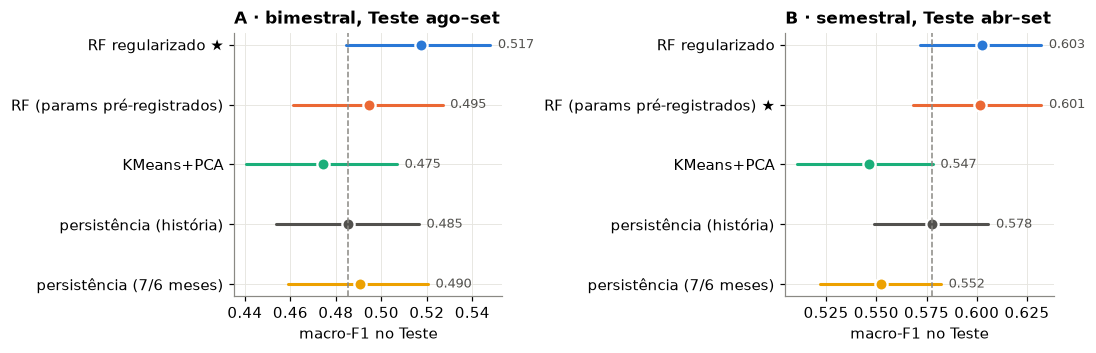

★ = vencedor da seleção v2 r2. Linha tracejada = persistência (história). Não compare A com B: os alvos diferem.


In [14]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.3), sharey=False)
for ax, d, tit in zip(axs, ("A_mesmo_alvo", "B_semestral"), ("A · bimestral, Teste ago–set", "B · semestral, Teste abr–set")):
    te = v2[d]["teste"]
    ordem = ["rf_regularizado", "rf_original", "kmeans_pca", "base_persistencia_historia", "base_persistencia_recente"]
    lin = [(NOME[m] + (" ★" if m == v2[d]["vencedor_selecao"] else ""), te[m]["macro_f1"]["valor"],
            te[m]["macro_f1"]["ic95"], m) for m in ordem]
    floresta(ax, lin, tit, ref=te["base_persistencia_historia"]["macro_f1"]["valor"])
plt.tight_layout(); plt.show()
print("★ = vencedor da seleção v2 r2. Linha tracejada = persistência (história). Não compare A com B: os alvos diferem.")

**MLflow:** experimento 3, os dois desenhos lado a lado no MLflow (runs `A_mesmo_alvo · …` e `B_semestral · …`).

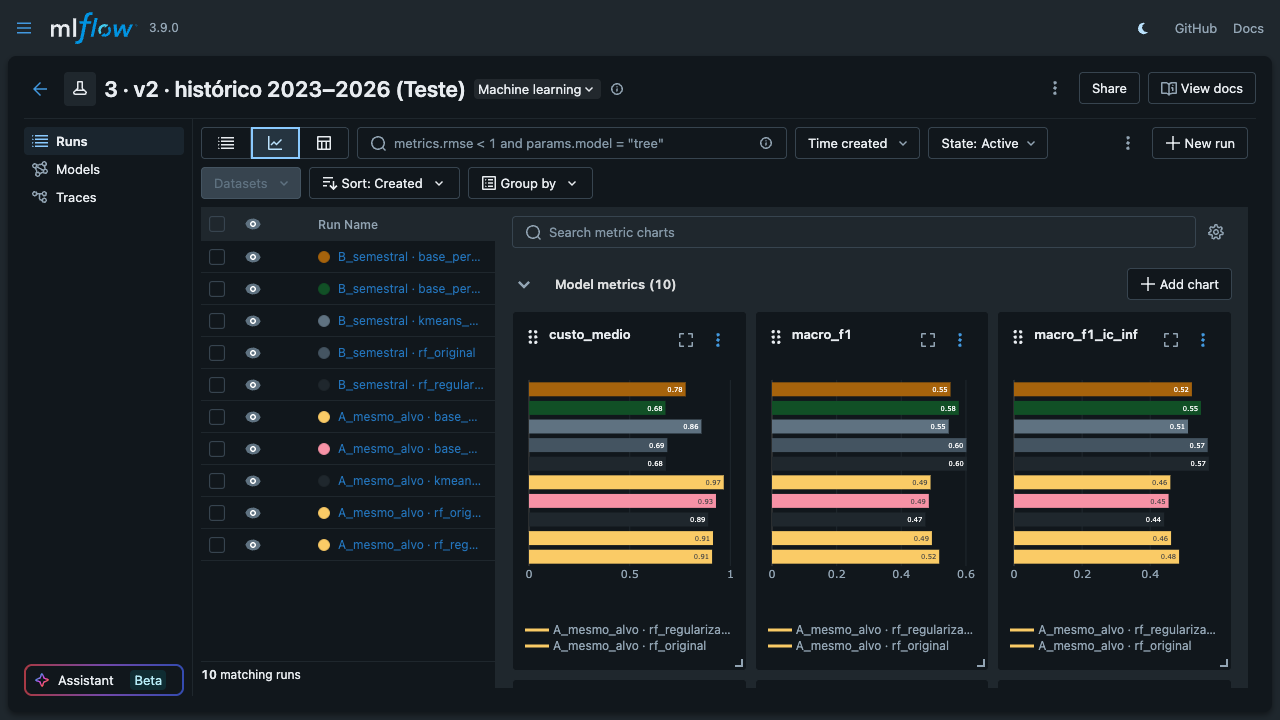

In [15]:
mostrar_print("03_v2_desenhos_A_B.png", "experimento 3, os dois desenhos lado a lado no MLflow (runs `A_mesmo_alvo · …` e `B_semestral · …`).")

### 5.1 Comparação primária: vencedor − persistência (história)

Esta é a única comparação fixada de antemão para cada desenho. Ela usa bootstrap pareado por célula res9 e por bloco
res7 (9 blocos).

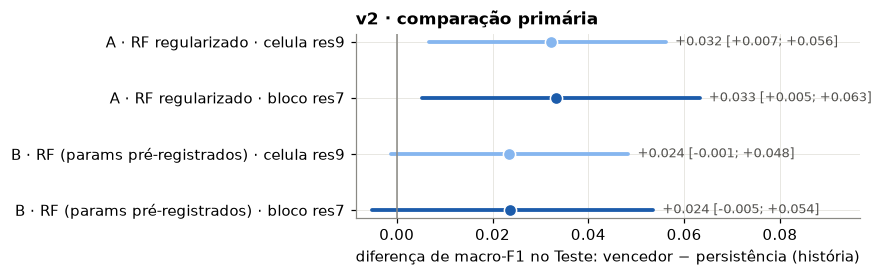

In [16]:
fig, ax = plt.subplots(figsize=(8, 2.6))
k = 0; rot = []
for d in ("A_mesmo_alvo", "B_semestral"):
    cp = v2[d]["comparacao_primaria"]
    for nivel, cor in (("celula_res9", "#86b6ef"), ("bloco_res7", "#1c5cab")):
        par = next(iter(cp[nivel])); r = cp[nivel][par]["macro_f1"]
        ax.plot(r["ic95"], [k, k], color=cor, lw=2.5, solid_capstyle="round")
        ax.plot(r["media"], k, "o", ms=8, color=cor, mec="white")
        ax.annotate(f"{r['media']:+.3f} [{r['ic95'][0]:+.3f}; {r['ic95'][1]:+.3f}]", (r["ic95"][1], k), xytext=(6, 0),
                    textcoords="offset points", va="center", fontsize=8.5, color="#52514e")
        rot.append(f"{d[0]} · {NOME[v2[d]['vencedor_selecao']]} · {nivel.replace('_', ' ')}"); k += 1
ax.axvline(0, color="#8a8984", lw=1); ax.set_yticks(range(k), rot); ax.invert_yaxis()
ax.set_xlim(right=ax.get_xlim()[1] + .03)
ax.set_xlabel("diferença de macro-F1 no Teste: vencedor − persistência (história)")
ax.set_title("v2 · comparação primária", loc="left"); plt.tight_layout(); plt.show()

**Leitura.**
- **A:**
  - RF regularizado − persistência = +0,032.
  - IC por célula [+0,007; +0,056] e por bloco [+0,005; +0,063] (média por bloco +0,033). Os dois intervalos ficam
    acima de zero.
  - Como a seleção r2 não é cega ao Teste e só há 9 blocos, o resultado é **exploratório**. Ele indica um ganho
    pequeno a confirmar num Teste novo e intocado.
- **B:**
  - RF (params pré-registrados) − persistência = +0,024.
  - Os ICs cruzam zero: [−0,001; +0,048] por célula e [−0,005; +0,054] por bloco.
  - É **inconclusivo**. Não há base para dizer que B ganha da persistência.
- **Multiplicidade:**
  - As comparações secundárias de `diferencas_secundarias` têm IC de Bonferroni.
  - Os ICs primários não são ajustados entre os dois desenhos.

### 5.2 A × v1 nas mesmas chaves (não é ablação)

Mesmas 847 chaves e mesmos rótulos no Teste. Ainda assim, **mudou o pipeline inteiro**: a história nas variáveis,
as variáveis extras, as origens e o tamanho do treino. A diferença não isola o efeito de "mais histórico".

### 5.3 Ablação da história no desenho A

Para isolar o efeito do histórico, o pipeline A foi rodado de novo com **as mesmas origens e os mesmos cortes**,
mas com cada variável enxergando só os **7 meses** anteriores à origem.

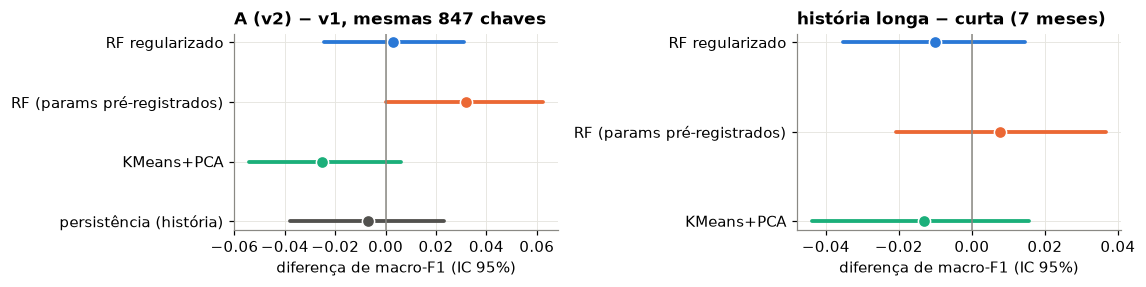

In [17]:
fig, axs = plt.subplots(1, 2, figsize=(10.5, 2.7))
dp = v2["A_vs_v1_mesmas_chaves"]["diferencas_pareadas"]
ab = v2["ablacao_historia_A"]["diferencas_pareadas"]
for ax, dic, tit in ((axs[0], dp, "A (v2) − v1, mesmas 847 chaves"), (axs[1], ab, "história longa − curta (7 meses)")):
    for i, (par, r) in enumerate(dic.items()):
        m = next(k for k in ("rf_regularizado", "rf_original", "kmeans_pca", "persistencia") if k in par)
        c = COR.get(m, COR["base_persistencia"])
        r = r["macro_f1"]
        ax.plot(r["ic95"], [i, i], color=c, lw=2.5, solid_capstyle="round")
        ax.plot(r["media"], i, "o", ms=8, color=c, mec="white")
    ax.axvline(0, color="#8a8984", lw=1)
    ax.set_yticks(range(len(dic)), [NOME.get(m, m) for m in
                  [next(k for k in ("rf_regularizado", "rf_original", "kmeans_pca", "base_persistencia_historia") if k.split("_")[-1] in p or k in p) for p in dic]])
    ax.invert_yaxis(); ax.set_title(tit, loc="left"); ax.set_xlabel("diferença de macro-F1 (IC 95%)")
plt.tight_layout(); plt.show()

**MLflow:** experimento 4, história longa × curta por modelo; as barras quase iguais são coerentes com o resultado inconclusivo. O texto cinza no campo de busca é o exemplo padrão do MLflow, não um filtro.

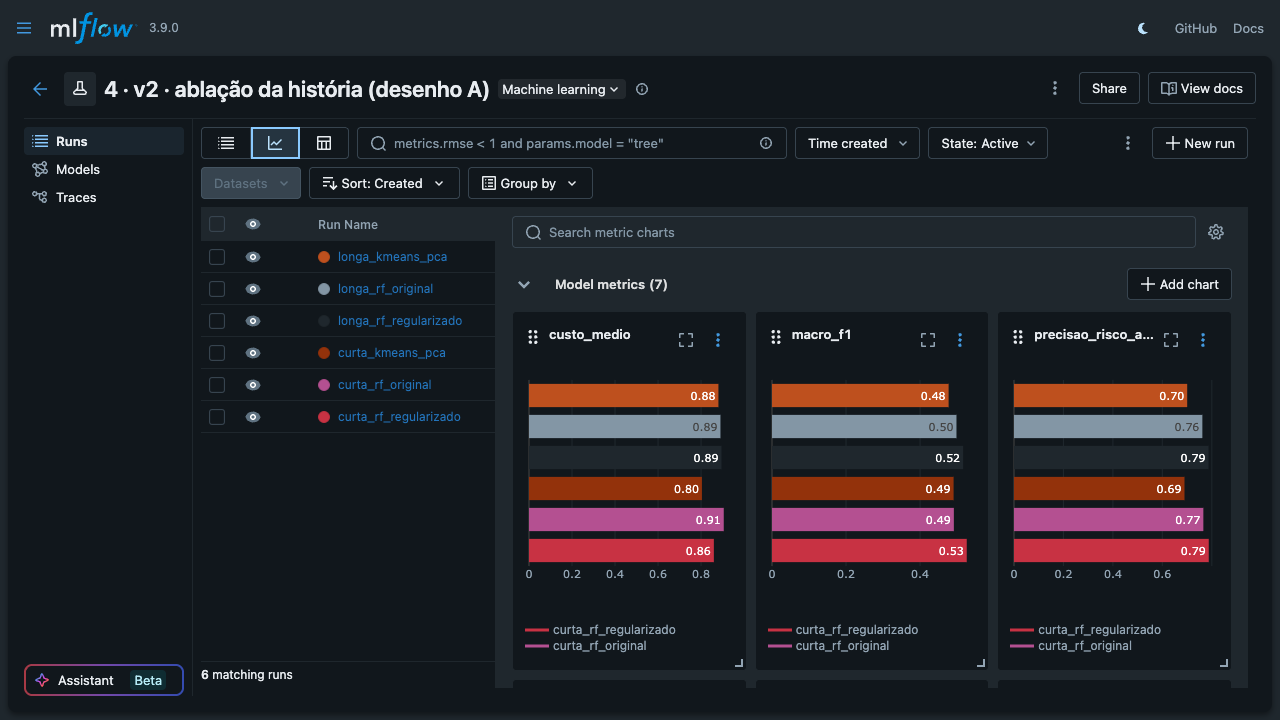

In [18]:
mostrar_print("04_v2_ablacao_historia.png", "experimento 4, história longa × curta por modelo; as barras quase iguais são coerentes com o resultado inconclusivo. O texto cinza no campo de busca é o exemplo padrão do MLflow, não um filtro.")

**Leitura.**
- **A × v1:**
  - RF regularizado: +0,003, IC [−0,025; +0,031], inconclusivo.
  - RF com params pré-registrados: +0,032, IC [0,000; +0,063]. Com Bonferroni o intervalo cruza zero.
- **Ablação:**
  - RF regularizado: −0,010, IC [−0,035; +0,015].
  - RF original: +0,008.
  - KMeans: −0,013.
  - Todos os intervalos cruzam zero.
- **O que pode ser dito:** *neste experimento, não foi observada evidência clara de que mais história nas variáveis
  melhore o macro-F1.*
- **O que não pode ser dito:** que "mais histórico não ajuda". Um IC que cruza zero não demonstra ausência de efeito.

## 6. Visão geral no MLflow

Os quatro experimentos registrados mostram a progressão do projeto:
1. Seleção v1 (CV).
2. Teste v1.
3. v2 nos desenhos A e B.
4. Ablação.

Cada run traz a proveniência separada:
- `commit_registrador`: commit em que o registrador rodou.
- `arquivo_fonte` e `sha256_fonte`: o arquivo de resultados lido e o hash dele.
- `commit_ultima_alteracao_fonte`: último commit que alterou esse arquivo.
- `commit_resultados`: só nos runs v2, o commit gravado pela própria execução em `v2_historico.json`. Para reproduzir:

```bash
~/.venvs/hoodi-mlflow/bin/python scripts/registrar_mlflow.py
~/.venvs/hoodi-mlflow/bin/mlflow ui --backend-store-uri sqlite:///mlflow/mlflow.db --port 5055
```
O banco `mlflow/` não é versionado. A fonte da verdade são os JSON e CSV em `ml/dados/resultados/`.

## 7. Conclusões permitidas e proibidas

| pode afirmar | não pode afirmar |
|---|---|
| O RF pré-registrado não superou a persistência no Teste v1. | Que algum modelo da exploração adicional é o "vencedor oficial". |
| O alvo res9 × 5 faixas × bimestre é ruidoso: o rótulo se repete com macro-F1 de 0,39–0,49 sem modelo. | Que a repetibilidade é um teto do desempenho. |
| No desenho A, o RF regularizado ficou +0,032 acima da persistência, como observação **exploratória** a confirmar. | Que esse ganho é confirmatório: a seleção r2 não é cega e há só 9 blocos. |
| No desenho B, a diferença para a persistência é inconclusiva. | "Ganho real" ou "significativo" de B. |
| Neste experimento, não se observou evidência clara de melhora com mais história nas variáveis. | "Mais histórico não ajuda." |
| As variáveis usam só meses anteriores ao início do rótulo, em backtest retrospectivo. | "Ausência de vazamento" ou disponibilidade operacional histórica dos dados. |
| A importância por permutação aponta a taxa de pontuação da chave como principal pista. | Ranking definitivo ou relação causal das variáveis. |

**Recomendação para a entrega (decisão do usuário):**
- Manter o **RF pré-registrado** como modelo oficial da v1, com o resultado honesto de que não superou a linha de base.
- Apresentar o RF regularizado e o desenho A como **hipóteses** para um Teste futuro intocado, por exemplo
  out–nov/2026.
- Se o objetivo for um alvo menos ruidoso, a agregação maior (res8 ou dia/noite) é o caminho com mais evidência.

## 8. Calibração e backtest agregado (exploração adicional)

O RF regularizado foi escolhido depois de ago–set ter sido visto (`test_seen=true`). As probabilidades abaixo servem
para diagnóstico; não alimentam o mapa observado entregue ao app. A isotônica foi ajustada somente com previsões fora
da dobra da CV temporal e foi rejeitada porque piorou as métricas no Teste já visto.

In [19]:
linhas_cal = []
for chave, nome in (("sem_calibracao", "sem calibração"), ("isotonica_cv", "isotônica da CV")):
    d = cal[chave]
    linhas_cal.append({"variante": nome, "Brier multiclasse": d["brier_multiclasse"],
                       "log-loss": d["log_loss"], "ECE": d["ece_nivel_mais_provavel"],
                       "Brier P(nível 3)": d["brier_nivel3"]})
display(pd.DataFrame(linhas_cal).round(3))

acc = bt_cal[bt_cal.modelo.isin(["rf_regularizado", "persistencia"])].copy()
acc["modelo"] = acc.modelo.map({"rf_regularizado": "RF regularizado", "persistencia": "persistência"})
display(acc.set_index("modelo")[["acerto_exato", "erro_le_1_nivel"]].mul(100).round(1))
display(pd.DataFrame(cal["estratos"]["por_faixa"]).round(3))
display(pd.DataFrame(cal["estratos"]["por_registros_na_janela_de_features"]).round(3))

,variante,Brier multiclasse,log-loss,ECE,Brier P(nível 3)
0,sem calibração,0.591,1.044,0.047,0.109
1,isotônica da CV,0.602,1.131,0.105,0.112


,acerto_exato,erro_le_1_nivel
modelo,,
persistência,50.2,87.5
RF regularizado,52.3,88.7


,faixa,faixa_nome,n,f1_rf_regularizado,f1_persistencia
0,0,madrugada,129,0.525,0.528
1,1,manha,179,0.514,0.506
2,2,tarde,210,0.540,0.509
3,3,noite_cedo,180,0.404,0.499
4,4,noite,149,0.390,0.347


,registros,n,f1_rf_regularizado,f1_persistencia,acerto_exato_rf
0,1,47,0.268,0.210,0.745
1,2-4,151,0.358,0.205,0.576
2,5+,649,0.443,0.445,0.495


**Leitura.**
- ECE 0,047 sem calibração; a isotônica piora para 0,105 e não é aplicada.
- O RF regularizado acerta o nível exato em 52,3% das chaves e fica a no máximo um nível em 88,7%; a persistência
  fica em 50,2% e 87,5%, respectivamente. A diferença de macro-F1 para a persistência não ficou estabelecida.
- A faixa 18–21h tem a maior desvantagem observada frente à persistência; o menor F1 do RF ocorre em 21–24h.
  Estratos por contagem são diagnósticos e não demonstram a causa das diferenças.
- O CSV de backtest contém somente métricas agregadas por modelo: não publica H3, faixa, rótulo nem contagem por chave.

### 8.1 Rastreabilidade

| item | onde |
|---|---|
| seleção pré-registrada v1 | `ml/dados/resultados/selecao_modelo.json` (nunca reescrito) |
| seleção v2 r2 / r1 | `selecao_v2_r2.json` / `selecao_v2.json` (histórico) |
| resultados v2, manifesto SHA-256, commit | `v2_historico.json` |
| achados da revisão | `achados_revisao.json` |
| red-team (Codex CLI, revisão real) | `docs/REDTEAM-V2-rodada*.md` |
| testes | `tests/` (`test_schema_processed.py`, `test_v2_historico.py`) |

In [20]:
print("commit dos resultados v2:", v2["commit"]["head"][:10], "| código alterado sem commit:", v2["commit"]["codigo_alterado_sem_commit"])
print("arquivos com hash no manifesto:", len(v2["manifesto_dados"]))

commit dos resultados v2: 0dad95eb18 | código alterado sem commit: False
arquivos com hash no manifesto: 10


## 9. Da previsão retrospectiva à decisão no app

**Escolha.** Em 15/11 o Nando definiu duas intenções para o app:
1. avisar a pessoa **antes** de entrar numa região com muitas ocorrências registradas;
2. entre 3–4 rotas de carro, escolher a de melhor índice de ocorrências.

Esta seção registra, sem retocar, o que a solução das seções 1–8 entrega para essas duas decisões
(proposta `docs/PROPOSTA-V3-ALERTA-ROTAS-r3.md`, revisada em 3 rodadas de red-team real do Codex).

**Veredito (r3 §0): a solução v1/v2 não implementa nem valida nenhuma das duas decisões.** Ela tem insumos que uma
decisão futura pode usar; a decisão em si não existia.

| necessidade | o que existia | o que faltava |
|---|---|---|
| Alerta de entrada | O snapshot do app é o **mapa histórico observado** de jan–set/2026 (contrato v2 com supressão k ≥ 3, `natureza`: "não é previsão"). | Regra de alerta (limiar, orçamento de alertas, antecedência) e avaliação dessa regra. O classificador ML não entra no contrato do app. |
| Escolha entre rotas de carro | Nada. Pontuação de rota estava fora de escopo (`SPEC-ML.md` §11, FR-012). | Pontuação de rota, contrato com a API, avaliação de ordenação e um evento definido como relevante para quem está dentro de um carro. |

**Números da r3 §1** (`ml/dados/resultados/conduta_local_2026.json`): das 20.343 ocorrências usadas na modelagem
(jan–set/2026), 89% são em via pública e só **6,8%** têm conduta ligada a veículo. Ou seja, o dado descreve
sobretudo o pedestre; usá-lo para rotas de carro é uma escolha de produto, não uma conclusão do dado.

### Arquitetura decidida

```
SSP-SP XLSX ──► pipeline ML (Python, lote, offline) ──► snapshot v2 (k ≥ 3) + manifest + sha256
                                                              │
                                                              ▼
                                          API .NET (Abner): ingere e serve o snapshot;
                                          contexto Rotas (RouteRequest/RouteSuggestion, RF-07)
                                                              │  download periódico (RF-04)
                                                              ▼
                                          App Expo: geofencing local, alerta offline (RNF-03),
                                          notificação do celular → smartwatch / hoodi Pet
```

- O ML **não** vira serviço: entrega artefatos versionados com sha256.
- O alerta é avaliado **no aparelho**, a partir do último snapshot.
- A rota é calculada pela **API**; o motor de rotas **não foi escolhido**.
- A decisão de privacidade de 16/11 substitui o snapshot v1 pelo contrato v2 antes da integração com API/app.

| artefato | define | executa em produção | vínculo | status |
|---|---|---|---|---|
| Snapshot v2 (k ≥ 3) | ML | API serve, app consome | `csv_sha256` no manifest | substitui o v1 antes da integração |
| Política de proximidade (bloco A) | ML | App | `politica_proximidade_v2.json` carrega `snapshot_csv_sha256`; hash diferente → o app não alerta e registra o erro | arquivo pronto; a forma de servir depende da API |
| Pontuação de rota (bloco B) | ML: especificação, referência Python, vetores-ouro | API, em C# | `rota_pontuacao_v1.md` + `vetores_rota_v2.json` com sha256 | **referência para validação**, não integração |

**Fora da responsabilidade do ML e não concluído:** motor de rotas, contrato HTTP de rotas, implementação em C# e
teste dela contra os vetores-ouro, a forma como a API serve a política, o consumo dos arquivos no app.

### Universos de avaliação (r3 §2.1)

Não há medida de cobertura da coleta: "zero" é sempre **zero registrado**. Os universos são filtros de registro
anterior, não de cobertura:
- **U1 (primário):** chave célula×faixa com ≥ 1 registro pontuável na mesma faixa nos 12 meses anteriores à janela-alvo.
  Usa só o passado, mas favorece métodos baseados em histórico.
- **U0 (sensibilidade):** só chaves com registro na janela-alvo (recorte da v1; exclui os zeros).
- **U2 (sensibilidade):** todas as células do perímetro × 5 faixas.

Se a conclusão muda entre U0, U1 e U2, ela é declarada frágil.

### Fase 2 (não feita nesta entrega)
- Teste futuro intocado (por exemplo out–nov/2026) para qualquer afirmação confirmatória.
- Trajetos reais e malha viária: orçamento de alertas medido em trajetos, alerta direcional, antecedência.
- Faixa por horário de passagem na rota; evento definido para quem está dentro de um carro.

### O que não se afirma
- Que o app avisa com antecedência ou distância mínima.
- Que alguma área ou rota está livre de ocorrências; o mapa mostra **ocorrências registradas**, retrospectivas.
- Que a política ou a pontuação de rota foram validadas com pessoas ou trajetos.
- Que os blocos A, B e C são modelos de produção: são **demonstrações retrospectivas exploratórias**, `test_seen=true`.

## 10. Demonstração: proximidade e pontuação de rota

> **Demonstração retrospectiva, não validada, `test_seen=true`.** Usa o snapshot v2 com supressão k ≥ 3 (jan–set/2026), que inclui o
> período do Teste já visto. Nada aqui mede comportamento de pessoas nem de trajetos.

### 10.1 Política de proximidade (bloco A)

**Escolha (decisão do Nando, 15/11, registrada em `docs/DECISOES-V3.md`: aditivo A "sim", `L = 3`; blocos B e C também aprovados):**
- `L = 3`: elegível = chave com `status=com_dado` e `nivel ≥ 3`.
- Anel `k = 1`: avisa se a célula atual ou uma vizinha for elegível.
- Cooldown de 30 min por célula elegível.
- Faixa pela hora de São Paulo, bordas `[início, fim)`.
- `sem_dado` nunca dispara e aparece como "dados insuficientes para exibição", sem revelar se houve supressão.
- Código: `ml/politica_proximidade.py`; contrato: `docs/contratos-v3/politica_proximidade_v2.json`.

In [21]:
import sys
sys.path.insert(0, str(RAIZ))
from ml import politica_proximidade as P, rota as R

pol = json.loads((RAIZ / "docs" / "contratos-v3" / "politica_proximidade_v2.json").read_text())
snap = P.ler_snapshot()
assert pol["snapshot_csv_sha256"] == P.sha256_arquivo(P.SNAPSHOT_CSV), "política não confere com o snapshot"

tab_L = pd.DataFrame(pol["tabela_por_L"]).set_index("L")
tab_L["% chaves com_dado"] = (100 * tab_L.fracao_chaves_com_dado).round(1)
tab_L["% da pontuação somada"] = (100 * tab_L.fracao_pontuacao).round(1)
display(Markdown("**Chaves elegíveis por L** (frações de chaves históricas; não é orçamento de área nem de alertas):"))
display(tab_L[["chaves_elegiveis", "chaves_com_dado", "% chaves com_dado", "% da pontuação somada"]])
p90 = pol["sensibilidade_p90"]
display(Markdown(f"Sensibilidade, só registrada: com corte no P90 da pontuação ({p90['p90_pontuacao_mensal']:.3f}), "
                 f"{p90['chaves']} chaves ({100 * p90['fracao_chaves_com_dado']:.1f}%) e "
                 f"{100 * p90['fracao_pontuacao']:.1f}% da pontuação. A regra não usa esse corte."))

**Chaves elegíveis por L** (frações de chaves históricas; não é orçamento de área nem de alertas):

,chaves_elegiveis,chaves_com_dado,% chaves com_dado,% da pontuação somada
L,,,,
1,682,954,71.5,94.8
2,475,954,49.8,85.3
3,200,954,21.0,57.4


Sensibilidade, só registrada: com corte no P90 da pontuação (1.957), 96 chaves (10.1%) e 36.6% da pontuação. A regra não usa esse corte.

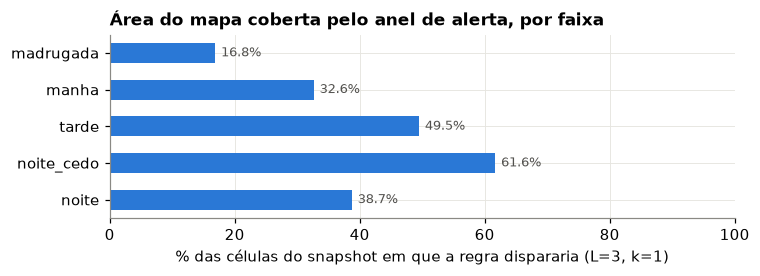

In [22]:
cob = pd.DataFrame(pol["cobertura_anel_por_faixa"])
fig, ax = plt.subplots(figsize=(7, 2.6))
ax.barh(cob.faixa_nome, 100 * cob.fracao, color="#2a78d6", height=0.55)
for i, v in enumerate(100 * cob.fracao):
    ax.annotate(f"{v:.1f}%", (v, i), xytext=(4, 0), textcoords="offset points", va="center", fontsize=8.5, color="#52514e")
ax.invert_yaxis(); ax.set_xlim(0, 100)
ax.set_xlabel("% das células do snapshot em que a regra dispararia (L=3, k=1)")
ax.set_title("Área do mapa coberta pelo anel de alerta, por faixa", loc="left")
plt.tight_layout(); plt.show()

**Leitura.**
- Em `L=3`, as quantidades e frações atualizadas são as calculadas diretamente na tabela acima a partir da política v2.
- **Limitação principal:** com o anel `k=1`, a regra dispara em 17–62% das células do mapa conforme a faixa
  (61,6% em `noite_cedo`). Numa região de muitas ocorrências registradas, isso pode virar aviso frequente.
  Medir quantos avisos uma pessoa receberia exige trajetos reais (fase 2).
- A regra **não garante distância nem antecedência**: avisa quando a pessoa já está na célula elegível ou numa vizinha
  (célula res9 ≈ 175 m de aresta).

### 10.2 Pontuação de rota (bloco B, referência para a API)

**Escolha.** Contrato `docs/contratos-v3/rota_pontuacao_v1.md`, referência `ml/rota.py`:
- A polilinha é discretizada em passos de 5 m; cada passo vai para a célula H3 res9 do seu ponto médio.
- Pontuação acumulada observada = Σ `pontuacao_mensal` × km dentro da célula, na faixa escolhida.
- `sem_dado` e fora do perímetro somam zero e são reportados em %. Se **sem dado + fora da cobertura, somados,
  passam de 30%** do comprimento, a rota fica com **dado insuficiente** e sem posição.
- Menor pontuação fica em 1º. Empate (diferença relativa ≤ 1e-9) é resolvido por classes ancoradas no menor valor,
  depois pelo menor km (mesma regra) e por fim pela ordem de entrada (contrato §4).

Exemplo com três polilinhas fixas entre os mesmos dois pontos de São Paulo (não são rotas de um motor de rotas):

In [23]:
ex = {f: R.exemplo(snap, f) for f in range(5)}
nomes_fx = {f: n for f, n, *_ in P.C.FAIXAS}
t = ex[4][["metros_total", "pontuacao_acumulada_observada", "indice_por_km", "pct_sem_dado", "pct_fora_da_cobertura",
           "dado_insuficiente", "posicao"]]
display(Markdown("**Faixa noite (21h–24h):**")); display(t)
pos = pd.DataFrame({nomes_fx[f]: d.posicao for f, d in ex.items()})
display(Markdown("**Posição de cada polilinha por faixa** (a ordem muda com a hora):")); display(pos)

**Faixa noite (21h–24h):**

,metros_total,pontuacao_acumulada_observada,indice_por_km,pct_sem_dado,pct_fora_da_cobertura,dado_insuficiente,posicao
reta,1568.68,1.016186,0.647798,0.0,0.0,False,1
norte_depois_leste,2199.81,2.352177,1.069262,0.0,0.0,False,3
leste_depois_norte,2199.73,1.551390,0.705263,0.0,0.0,False,2


**Posição de cada polilinha por faixa** (a ordem muda com a hora):

,madrugada,manha,tarde,noite_cedo,noite
reta,2,1,1,1,1
norte_depois_leste,3,3,2,3,3
leste_depois_norte,1,2,3,2,2


In [24]:
vet = json.loads((RAIZ / "docs" / "contratos-v3" / "vetores_rota_v2.json").read_text())
h_vet = (RAIZ / "docs" / "contratos-v3" / "vetores_rota_v2.json.sha256").read_text().split()[0]
display(Markdown(
    f"**Vetores-ouro para a implementação em C#** (`vetores_rota_v2.json`, sha256 `{h_vet[:16]}…`): "
    f"{len(vet['casos'])} casos ({', '.join(c['nome'] for c in vet['casos'])}), "
    f"{len(vet['rotas_fronteira'])} rotas sobre bordas de célula, {len(vet['pontos_interiores'])} pontos interiores, "
    f"{len(vet['pontos_fronteira'])} pontos a ±5e-8° de arestas e {len(vet['empate_vetores'])} vetores de empate. "
    f"H3 core {vet['h3_core_c']}, resolução {vet['resolucao']}."))

**Vetores-ouro para a implementação em C#** (`vetores_rota_v2.json`, sha256 `93b1980b88eecae7…`): 10 casos (1_toda_com_dado, 2_trecho_sem_dado, 3_sai_do_perimetro, 4_cruza_bordas, 5_empate_e_ranking, 6_um_ponto, 7_pontos_repetidos, 8_segmento_menor_5m, 9_volta_mesma_celula, 10_faixa_3h), 2 rotas sobre bordas de célula, 20 pontos interiores, 20 pontos a ±5e-8° de arestas e 2 vetores de empate. H3 core 4.5.0, resolução 9.

**MLflow:** experimento 5, um run por bloco (`politica_proximidade_v2`, `rota_pontuacao_v1`, `ta_descritiva`), com tags `test_seen=true` e `natureza=demonstracao`. O texto cinza no campo de busca é o exemplo padrão do MLflow, não um filtro.

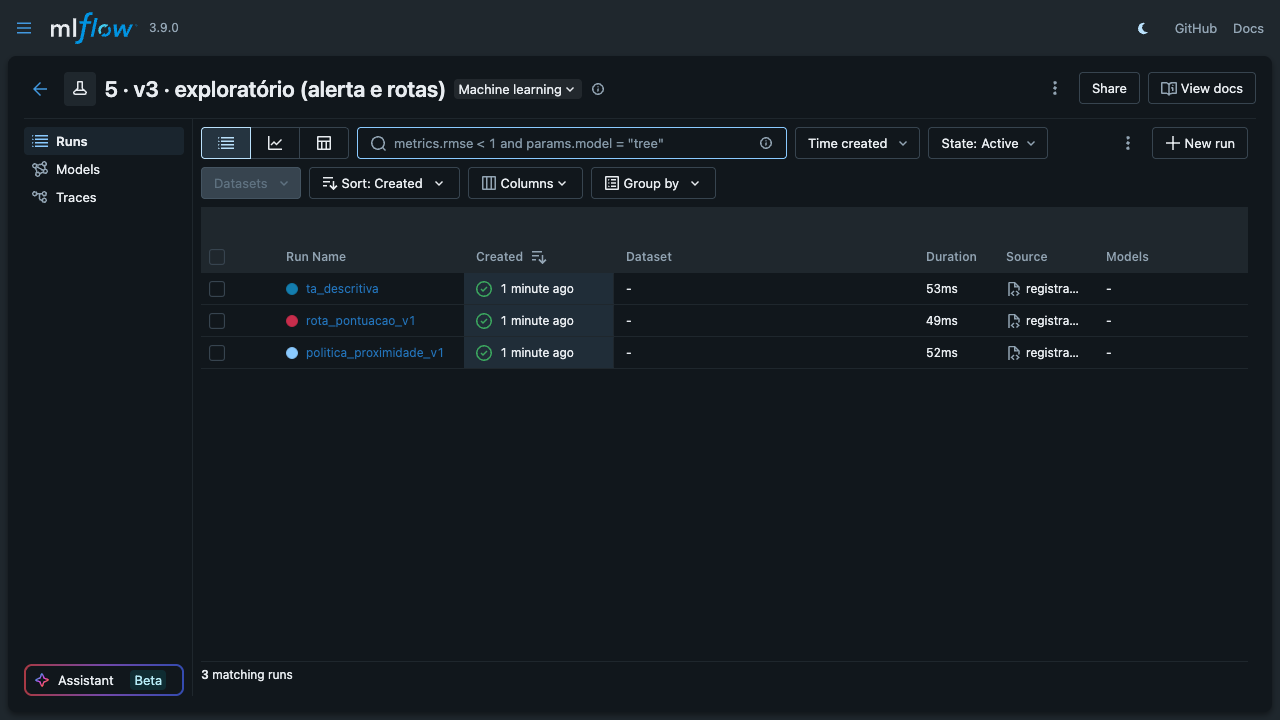

In [25]:
mostrar_print("05_v3_exploratorio.png", "experimento 5, um run por bloco (`politica_proximidade_v2`, `rota_pontuacao_v1`, `ta_descritiva`), com tags `test_seen=true` e `natureza=demonstracao`. O texto cinza no campo de busca é o exemplo padrão do MLflow, não um filtro.")

**Leitura.**
- A referência é **determinística** e reproduzível pelos vetores; ela define o cálculo que a API precisa reproduzir.
- O exemplo mostra que a polilinha mais curta não é sempre a 1ª: na madrugada ela fica em 2º, e na tarde as duas mais longas trocam de posição. São três desenhos
  fixos, não rotas reais; **nenhuma ordenação foi validada** contra ocorrências futuras ou trajetos.
- Integração (motor de rotas, endpoint, C#) é da API e não está concluída.

## 11. T-A descritiva: ordenar células para alerta (bloco C)

**Escolha (r3 §2.2).** Pergunta: se o app ordenasse as chaves célula×faixa por um escore calculado só com o passado,
quanto das ocorrências registradas da janela seguinte cairia nos 10% do topo?
- Alvo: pontuação da chave na janela bimestral seguinte (zero registrado = 0).
- Métrica: **hit rate a 10%** = Σ alvo das ⌈0,10·N⌉ chaves de maior escore ÷ Σ alvo do universo.
- Escores: persistência (bimestre anterior), média histórica (desde jan/2023), suavizada com vizinhas
  (λ escolhido em 2024 e congelado em `ta_lambda.json` antes das origens reportadas) e RF regularizado walk-forward.
- Origens reportadas: 10 bimestres, jan–fev/2025 a jul–ago/2026. **ago–set/2026 (Teste da v1) aparece à parte,
  como já vista.**
- **Descritiva:** sem intervalo de confiança, sem teste de hipótese, sem afirmação de superioridade.

In [26]:
ta, lam = ler("ta_descritiva.json"), ler("ta_lambda.json")
display(Markdown(f"λ escolhido nas origens de seleção = **{lam['lambda_escolhido']}** "
                 f"(média do hit rate em U1 por λ: {lam['media_hit_rate_10_U1_por_lambda']}). Com λ=0 a suavizada "
                 "coincide com a média histórica."))
COR_TA = {"persistencia": "#52514e", "media_historica": "#eda100", "suavizada": "#1baf7a", "rf_regularizado": "#2a78d6"}
NOME_TA = {"persistencia": "persistência", "media_historica": "média histórica", "suavizada": "suavizada (λ=0)",
           "rf_regularizado": "RF regularizado (exploratório)"}
linhas = []
for un in ("U1", "U0", "U2"):
    for m, r in ta["resumo_reportadas"][un].items():
        linhas.append({"universo": un, "método": NOME_TA[m], "mediana": round(r["mediana"], 3),
                       "mín": round(r["minimo"], 3), "máx": round(r["maximo"], 3),
                       "origens acima da persistência": f'{r["origens_acima_da_persistencia"]}/{r["n_origens"]}'})
display(Markdown("**Hit rate a 10% nas 10 origens reportadas:**"))
display(pd.DataFrame(linhas).set_index(["universo", "método"]))

λ escolhido nas origens de seleção = **0.0** (média do hit rate em U1 por λ: {'0.0': 0.3962859752855349, '0.25': 0.3934939224350599, '0.5': 0.38450408583260587, '0.75': 0.3603389461896161}). Com λ=0 a suavizada coincide com a média histórica.

**Hit rate a 10% nas 10 origens reportadas:**

mediana    mín    máx  \
universo método                                                  
U1       persistência                      0.365  0.334  0.381   
         média histórica                   0.383  0.352  0.420   
         suavizada (λ=0)                   0.383  0.352  0.420   
         RF regularizado (exploratório)    0.390  0.356  0.425   
U0       persistência                      0.292  0.273  0.321   
         média histórica                   0.307  0.287  0.348   
         suavizada (λ=0)                   0.307  0.287  0.348   
         RF regularizado (exploratório)    0.311  0.291  0.358   
U2       persistência                      0.408  0.381  0.425   
         média histórica                   0.425  0.392  0.459   
         suavizada (λ=0)                   0.425  0.392  0.459   
         RF regularizado (exploratório)    0.428  0.401  0.466   

                                        origens acima da persistência  
universo método                                                        
U1       persistência                                            0/10  
         média histórica                                         9/10  
         suavizada (λ=0)                                         9/10  
         RF regularizado (exploratório)                          9/10  
U0       persistência                                            0/10  
         média histórica                                         8/10  
         suavizada (λ=0)                                         8/10  
         RF regularizado (exploratório)                          9/10  
U2       persistência                                            0/10  
         média histórica                                         9/10  
         suavizada (λ=0)                                         9/10  
         RF regularizado (exploratório)                         10/10

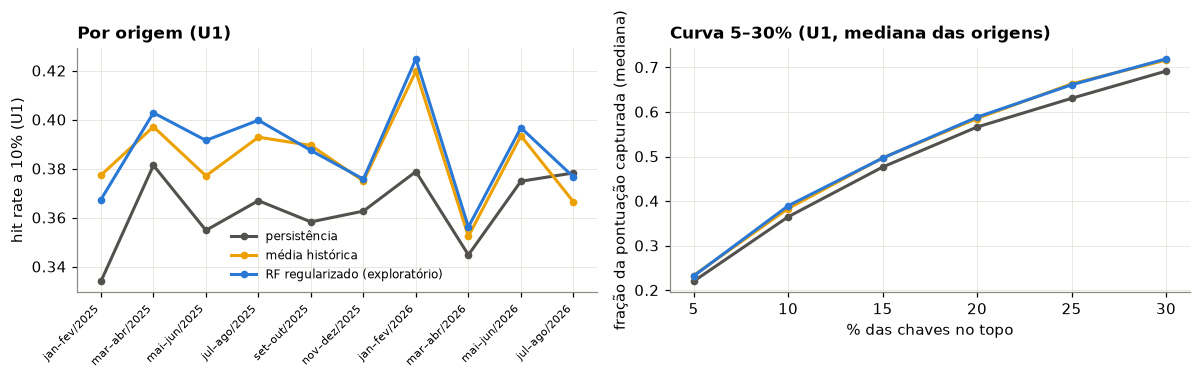

**ago–set/2026, já vista (não entra no resumo):** persistência 0.354, média histórica 0.359, suavizada (λ=0) 0.359, RF regularizado (exploratório) 0.378

In [27]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.4))
orig = ta["origens_reportadas"]
x = range(len(orig))
for m in ("persistencia", "media_historica", "rf_regularizado"):
    axs[0].plot(x, [o["universos"]["U1"]["hit_rate_10"][m] for o in orig], "-o", ms=4, lw=2,
                color=COR_TA[m], label=NOME_TA[m])
axs[0].set_xticks(list(x), [o["janela_alvo"] for o in orig], rotation=45, ha="right", fontsize=7.5)
axs[0].set_ylabel("hit rate a 10% (U1)"); axs[0].set_title("Por origem (U1)", loc="left")
axs[0].legend(fontsize=8, frameon=False)
fr = list(orig[0]["universos"]["U1"]["curva"]["persistencia"])
for m in ("persistencia", "media_historica", "rf_regularizado"):
    med = [np.median([o["universos"]["U1"]["curva"][m][f] for o in orig]) for f in fr]
    axs[1].plot([int(f[:-1]) for f in fr], med, "-o", ms=4, lw=2, color=COR_TA[m], label=NOME_TA[m])
axs[1].set_xlabel("% das chaves no topo"); axs[1].set_ylabel("fração da pontuação capturada (mediana)")
axs[1].set_title("Curva 5–30% (U1, mediana das origens)", loc="left")
plt.tight_layout(); plt.show()

vista = ta["ja_vista_ago_set_2026"]["universos"]["U1"]["hit_rate_10"]
display(Markdown("**ago–set/2026, já vista (não entra no resumo):** " +
                 ", ".join(f"{NOME_TA[m]} {v:.3f}" for m, v in vista.items())))

**Leitura.**
- Em U1, os 10% de chaves do topo pela **média histórica** capturam ~38% da pontuação da janela seguinte (mediana),
  contra ~36% da persistência, e ficam acima dela em 9 das 10 origens. U0 (8/10) e U2 (9/10) apontam na mesma direção,
  então a observação não é frágil entre universos.
- O RF regularizado fica um pouco acima (~39%), mas os hiperparâmetros dele foram escolhidos **depois** de ver
  ago–set/2026. Ele é exploratório e não sustenta superioridade sobre as linhas de base.
- **O que pode ser dito:** neste recorte retrospectivo, ordenar por média histórica concentrou mais ocorrências
  registradas no topo do que repetir o último bimestre. Isso apoia o snapshot como mapa histórico.
- **O que não pode ser dito:** que a diferença é significativa, que vale para o futuro, ou que mede utilidade de
  alertas para pessoas.

### Rastreabilidade v3

| item | onde |
|---|---|
| proposta e plano | `docs/PROPOSTA-V3-ALERTA-ROTAS-r3.md`, `docs/PLANO-EXECUCAO-V3-r2.md` |
| política de proximidade | `ml/politica_proximidade.py` → `docs/contratos-v3/politica_proximidade_v2.json` (+ `.sha256`) |
| pontuação de rota | `ml/rota.py`, `docs/contratos-v3/rota_pontuacao_v1.md`, `vetores_rota_v2.json` (+ `.sha256`) |
| T-A descritiva | `ml/ta_descritiva.py` → `ml/dados/resultados/ta_lambda.json`, `ta_descritiva.json` |
| MLflow | experimento `5 · v3 · exploratório (alerta e rotas)`, tag `experimento_logico=hoodi-v3-exploratorio` (o nome lógico do plano; ver `docs/DECISOES-V3.md`), `scripts/registrar_mlflow.py` |
| decisões do Nando | `docs/DECISOES-V3.md` |
| testes | `tests/test_politica_proximidade.py`, `tests/test_rota.py`, `tests/test_ta_descritiva.py` |
| red-team (Codex CLI, revisão real) | `docs/REDTEAM-V3-rodada*.md`, `docs/REDTEAM-PLANO-V3-rodada*.md`, `docs/REDTEAM-IMPL-V3-rodada*.md` |